After Read Count Filtering, analyze the difference in samples loss affecting the categories

Notes:
- Original category-sample sizes are copied and pasted in from archs4_project_LW20220108

In [6]:
# Read Data
import ast

root = "/Users/lwu/PycharmProjects/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/Analysis/After Read Filteration - Category Sample Sizes"

with open(root + "/category_totalSampleSize_dict_LW20230108.txt", "r") as file:
    # read the file contents
    data = file.read()
    # Use ast.literal_eval to safely evaluate the string as a dictionary
    org_sampleSize = ast.literal_eval(data)

with open(root + "/category_uniqueSelectedSamplesSizes_LW20230108.txt", "r") as file:
    # read the file contents
    data = file.read()
    # Use ast.literal_eval to safely evaluate the string as a dictionary
    filtered_sampleSize = ast.literal_eval(data)

In [13]:
# Get the difference

import operator

sampleSize_diff = {}

for key in org_sampleSize:
    if key in filtered_sampleSize:
        remaining_samples = org_sampleSize[key] - filtered_sampleSize[key]
        if remaining_samples != 0:
            sampleSize_diff[key] = remaining_samples/org_sampleSize[key]
        else:
            sampleSize_diff[key] = 0

# sort the result dictionary in descending order based on the values
sorted_sampleSize_diff = dict(sorted(sampleSize_diff.items(), key=operator.itemgetter(1), reverse=True))

# print the sorted result
print(sorted_sampleSize_diff)


{'Midbrain': 0.9680451127819549, 'Pancreatic Islet': 0.9487857142857142, 'Spleen': 0.919077568134172, 'Oligodendrocyte': 0.908256880733945, 'Esophagus': 0.900611620795107, 'Testis': 0.8881118881118881, 'NALM6': 0.8617021276595744, 'Retina': 0.8205267740531128, 'IMR90': 0.7879185817465528, 'Plasma Cell': 0.7860576923076923, 'ES2': 0.7780784844384303, 'Small Intestine': 0.7712895377128953, 'Thymocyte': 0.7272727272727273, 'IMR32': 0.6632302405498282, 'Brain': 0.6482583511862255, 'Myoblast': 0.6457789382071366, 'Neuron': 0.6390463917525773, 'Bone Marrow': 0.622843492877997, 'MDAMB468': 0.6209386281588448, 'JURKAT': 0.5729764181007011, 'Dendritic': 0.5674157303370787, 'Fibroblast': 0.5636173296827186, 'K562': 0.5361433917667914, 'Skin': 0.5348497305197771, 'Hepatocyte': 0.5269461077844312, 'Liver': 0.5182242000423819, 'MCF7': 0.5088944305901912, 'Lung': 0.47517084282460137, 'Ovary': 0.46586345381526106, 'Neutrophil': 0.440337909186906, 'Kidney': 0.42330272467258767, 'Alpha Cell': 0.3972602

In [16]:
print("Original:", org_sampleSize["Midbrain"])
print("Filtered:", filtered_sampleSize["Midbrain"])

Original: 2128
Filtered: 68


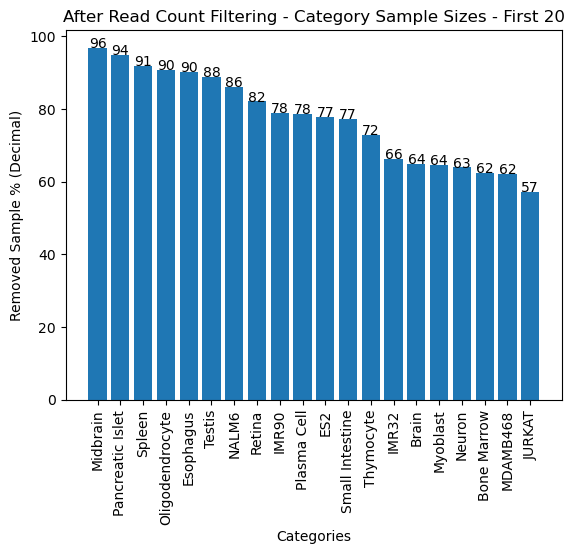

In [48]:
import matplotlib.pyplot as plt

# get the keys and values from the sorted result dictionary
keys = list(sorted_sampleSize_diff.keys())[0:20]
values = list(sorted_sampleSize_diff.values())[0:20]

# convert to percentage
values = [v * 100 for v in values]

# Add the value labels
for i, v in enumerate(values):
    plt.text(i, v, str(int(v)), ha='center')

# create the bar plot
plt.bar(keys, values)
plt.xlabel('Categories')
plt.xticks(rotation=90)
plt.ylabel('Removed Sample % (Decimal)')
plt.title('After Read Count Filtering - Category Sample Sizes - First 20')
plt.show()

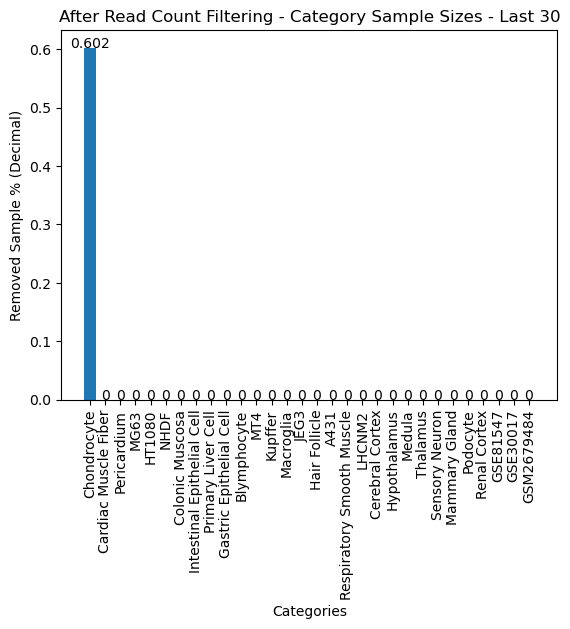

In [50]:
# get the keys and values from the sorted result dictionary
keys = list(sorted_sampleSize_diff.keys())[-30:]
values = list(sorted_sampleSize_diff.values())[-30:]

# convert to percentage
values = [v * 100 for v in values]

# Add the value labels
for i, v in enumerate(values):
    plt.text(i, v, str(round(v, 3)), ha='center')

# create the bar plot
plt.bar(keys, values)
plt.xlabel('Categories')
plt.xticks(rotation=90)
plt.ylabel('Removed Sample % (Decimal)')
plt.title('After Read Count Filtering - Category Sample Sizes - Last 30')
plt.show()

In [52]:
# Check rounding of the Chondrocyte
values = list(sorted_sampleSize_diff.values())[-30:]
print(values)
print(round(0.006024096385542169,2))

[0.006024096385542169, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
0.01


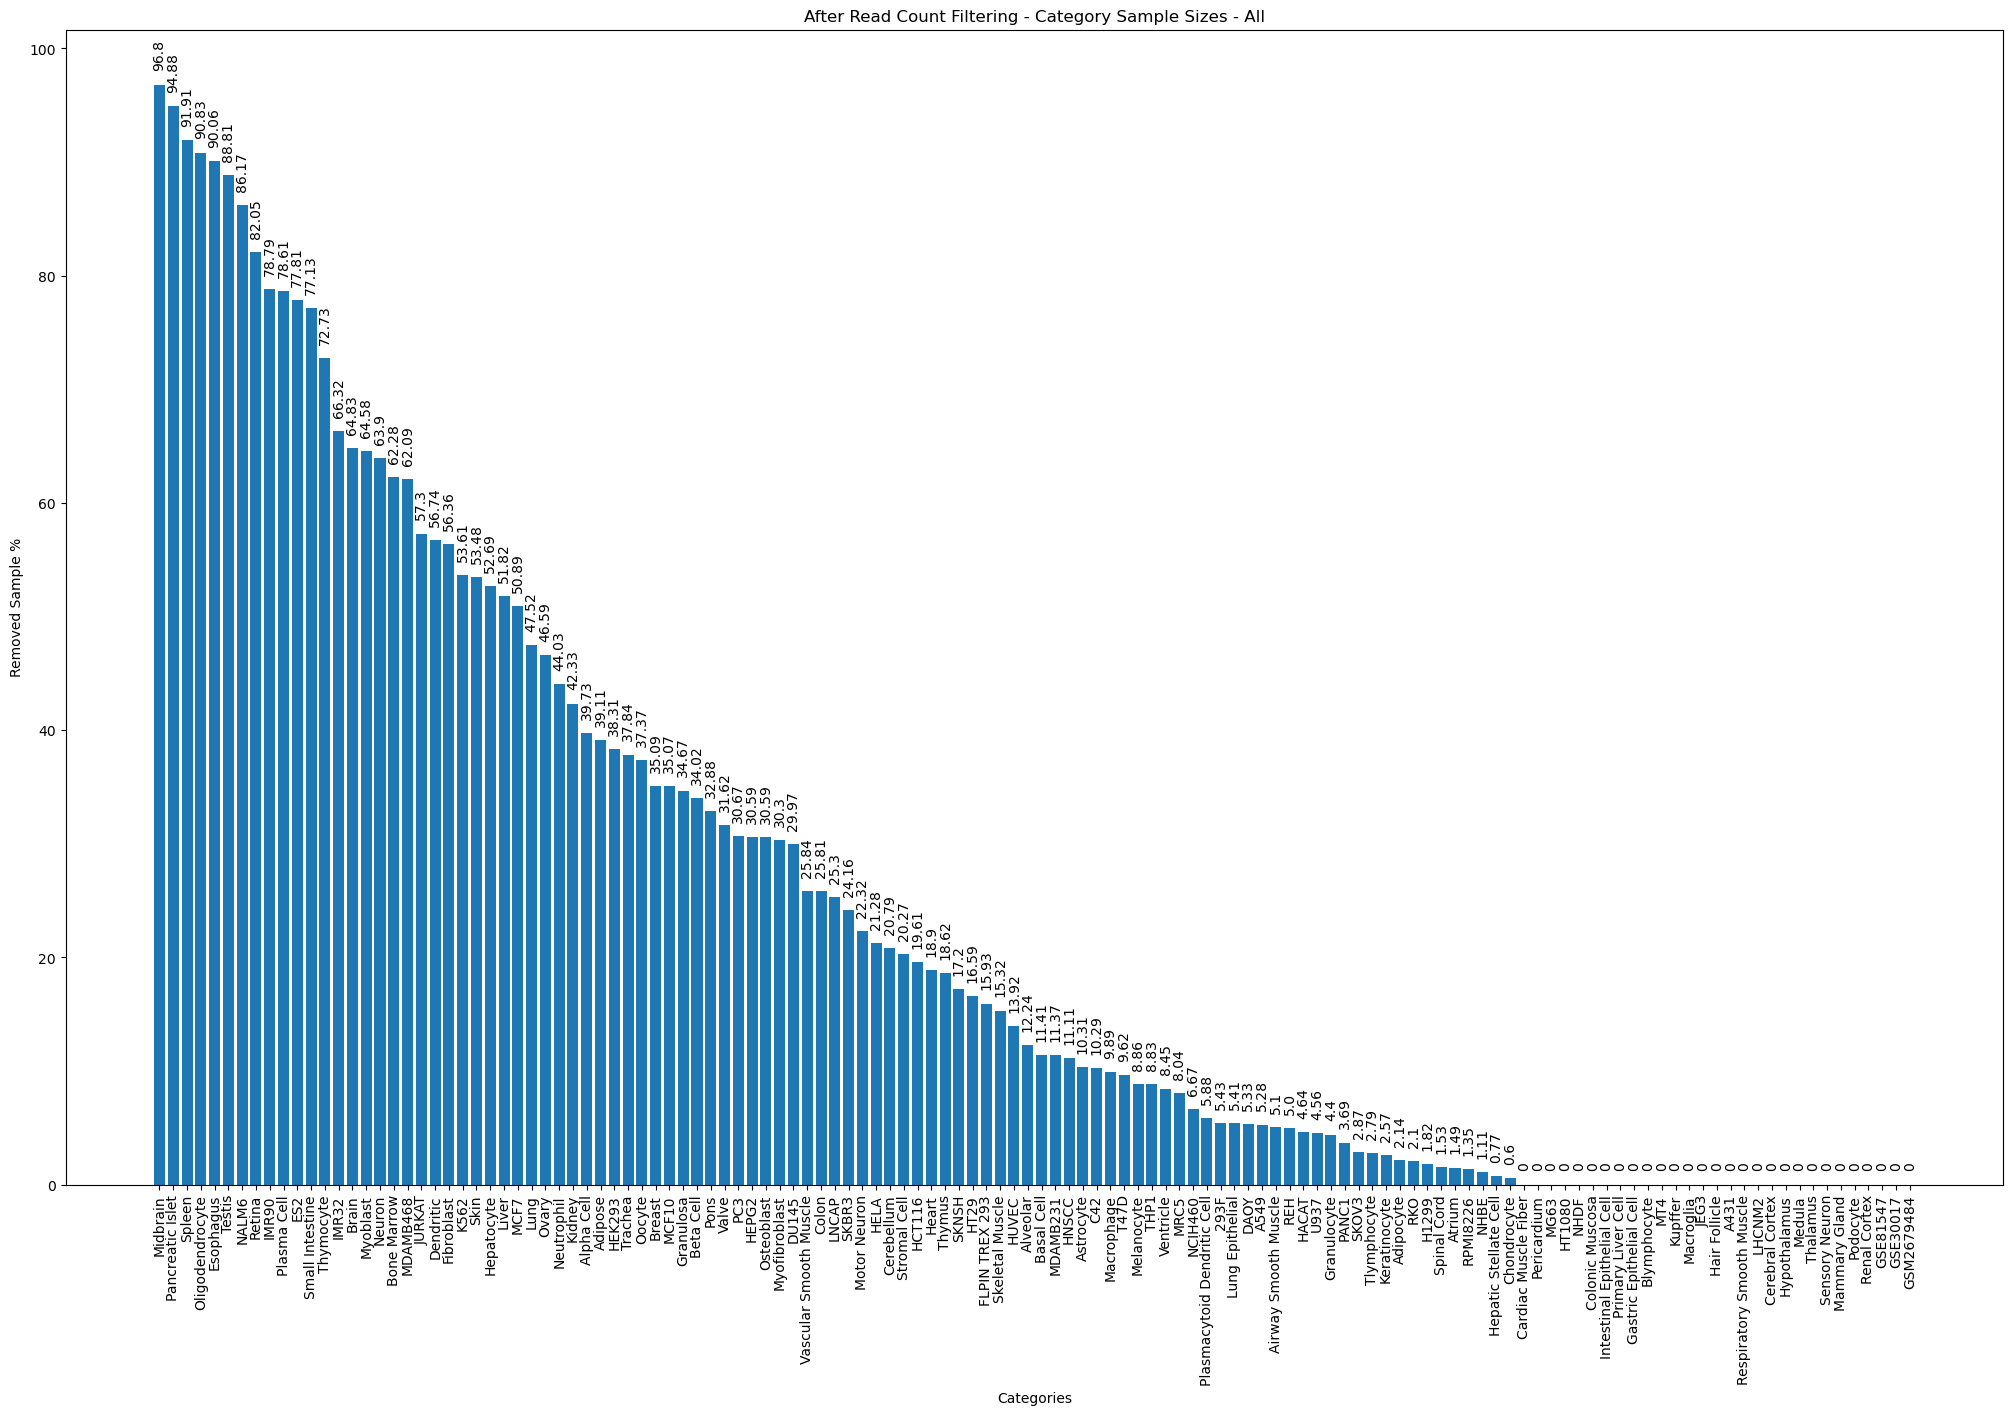

In [64]:
# get the keys and values from the sorted result dictionary
keys = list(sorted_sampleSize_diff.keys())
values = list(sorted_sampleSize_diff.values())

# convert to percentage
values = [v * 100 for v in values]

# Add the value labels
for i, v in enumerate(values):
    plt.annotate(str(round(v, 2)), xy=(i,v), xytext=(0,10), textcoords='offset points', ha='center', va='bottom', rotation = 90)

# create the bar plot
plt.bar(keys, values)
plt.xlabel('Categories')
plt.xticks(rotation=90)
fig = plt.gcf()
fig.set_size_inches(25, 15)
plt.ylabel('Removed Sample %')
plt.title('After Read Count Filtering - Category Sample Sizes - All')
plt.show()